# PMM 改善版：檢查結果與可重現預測

本輪完成 18 次訓練，以 2014、2015 驗證結果選出 **PMM_weighted / best**。
請從 `pmm` 資料夾開啟，選擇專案 `.venv` Python 核心。

本 notebook 預設讀取已完成結果並重載模型，**不重新訓練**。原始 `hierarchical_forecasting.ipynb` 與 `ＰＰＰ.ipynb` 保留。
2016 曾在前輪實驗中看過，因此這裡是重現／探索性比較，不能視為新的盲測。
完整細節見 [追加檢查結果](PMM_追加檢查結果.md)。


In [1]:
# 先設定專案內的執行緒、暫存與快取環境，再載入其他套件。
from pmm_robustness import (
    ROOT, OUT, CONFIGS, make_base, load_local_data, forecast,
)
import json
import pandas as pd
import torch
from IPython.display import display, Image
selection = json.loads((OUT / 'selection.json').read_text())
chosen = selection['selected_PMM']
print('驗證集選出的 PMM：', chosen)
print('模型設定：', CONFIGS[chosen['name']])


驗證集選出的 PMM： {'name': 'PMM_weighted', 'policy': 'best', 'mean_validation_scrps': 0.13146724013880348}
模型設定： {'loss': 'PMM', 'lr': 0.0003, 'weighted': True}


## 六組驗證結果

每個設定均使用 3 個真正重新訓練的種子與 2 個驗證年度。`mean_scrps` 越低越好。
`last` 是最後一步；`best` 是內部驗證指標最佳一步。內部指標與最終階層整合後的指標不同，所以 `best` 不保證更好。


,name,policy,runs,mean_scrps,std_scrps,min_scrps,max_scrps,mean_mae,mean_coverage90
0,GMM,best,6,0.123387,0.005756,0.116841,0.129433,63.493267,0.928228
1,GMM,last,6,0.125978,0.006295,0.119226,0.133244,64.293130,0.926076
2,PMM_fixed,best,6,0.351925,0.010352,0.342084,0.364859,215.493587,0.929655
3,PMM_fixed,last,6,0.398995,0.025713,0.375921,0.446449,247.803496,0.932332
4,PMM_weighted,best,6,0.131467,0.006631,0.124567,0.138212,66.223449,0.889815
5,PMM_weighted,last,6,0.134917,0.007499,0.125204,0.142656,66.863698,0.891116


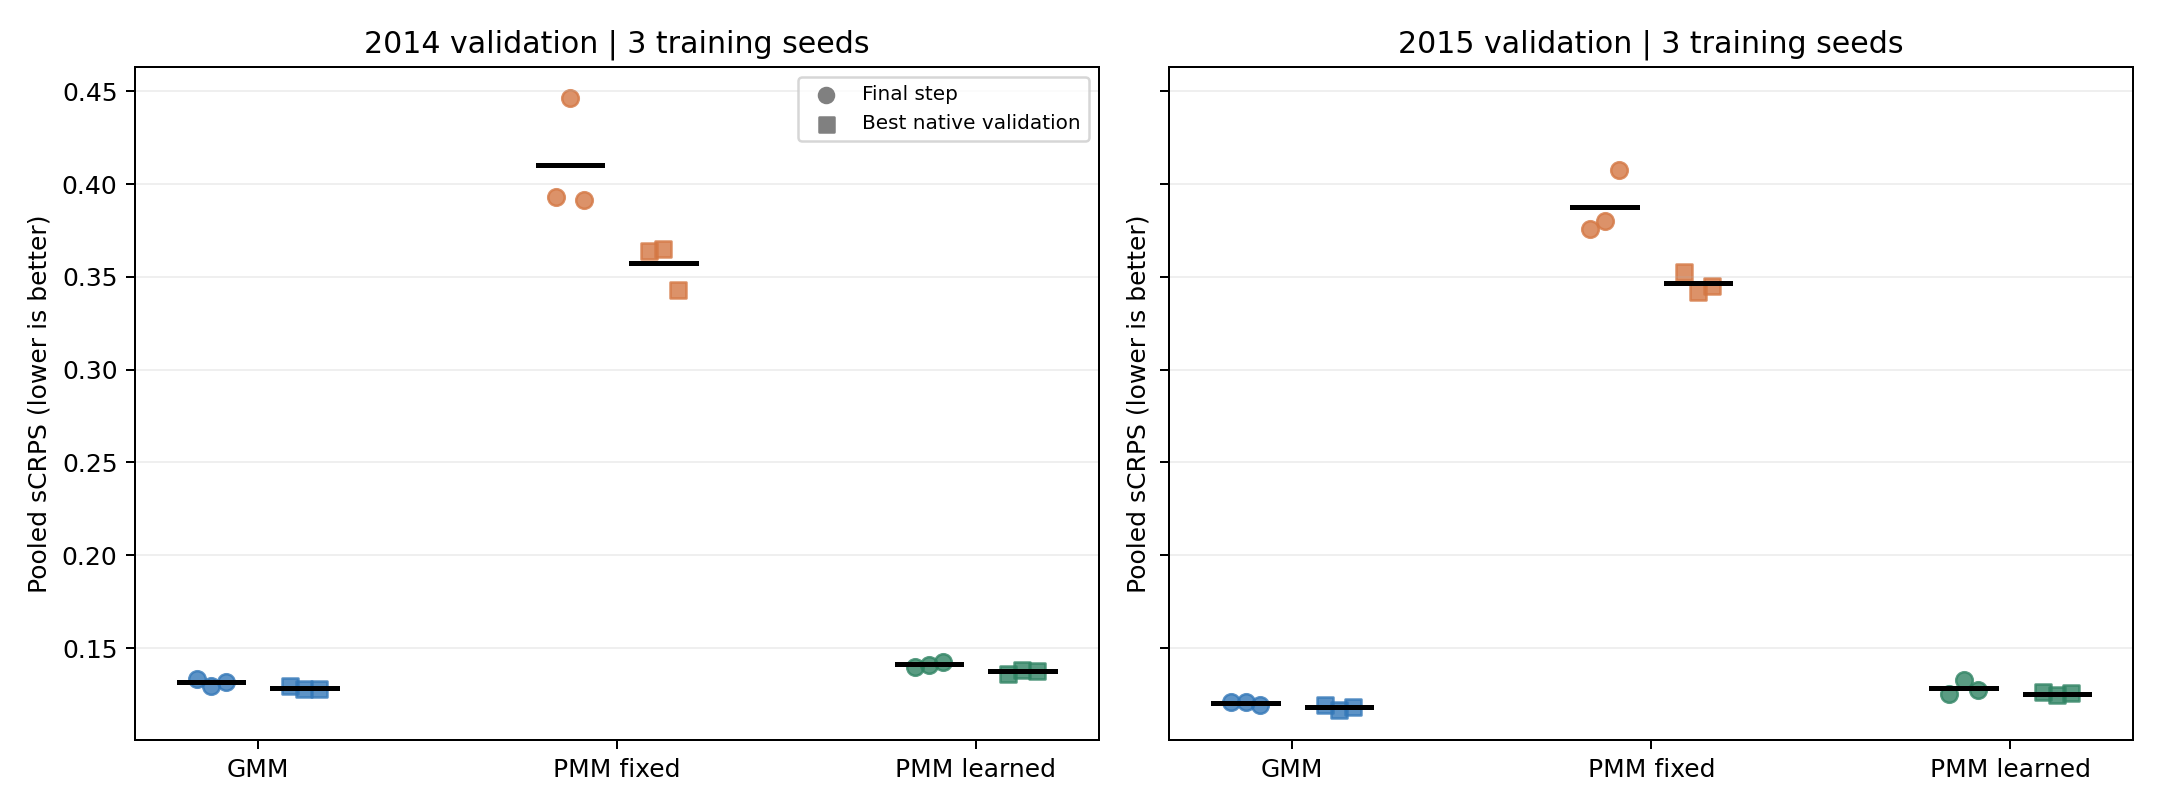

In [2]:
display(pd.read_csv(OUT / 'validation_summary.csv'))
display(Image(filename=str(OUT / 'validation_comparison.png')))


## 載入選定模型並重現預測

使用事先固定的訓練種子 1，以 2015 年底以前的歷史預測 2016；不挑測試分數最好的種子。
資料會先對齊 S 的順序；預測日期由歷史最後月份推算，不從待預測的真值取得。


In [3]:
training_seed = 1
Y, S, tags, audit = load_local_data()
history = Y[Y['ds'].dt.year < 2016].copy()
model_dir = OUT / 'runs' / f"{chosen['name']}_y2015_s{training_seed}"
base = make_base(CONFIGS[chosen['name']], training_seed)
base.trainer_kwargs['callbacks'] = []
base.load_state_dict(torch.load(
    model_dir / f"{chosen['policy']}_weights.pt", weights_only=True
))
prediction = forecast(base, history, S, sampling_seed=1)
display(prediction[['unique_id', 'ds', 'NHITS', 'NHITS-lo-90', 'NHITS-hi-90']].head(12))


/Users/cys/Desktop/meeting/pmm/.venv/lib/python3.10/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


,unique_id,ds,NHITS,NHITS-lo-90,NHITS-hi-90
0,TotalAll,2016-01-01,43509.738652,40656.757559,46736.205398
1,TotalAll,2016-02-01,21689.530114,19885.920008,23601.840487
2,TotalAll,2016-03-01,24295.491453,22580.067059,26177.201218
3,TotalAll,2016-04-01,29328.729419,27495.847967,31298.727883
4,TotalAll,2016-05-01,22968.259009,21412.564248,24777.329982
5,TotalAll,2016-06-01,23732.491893,22137.984939,25646.336371
6,TotalAll,2016-07-01,27172.437223,25286.271901,29399.262272
7,TotalAll,2016-08-01,24609.860262,22866.229692,26597.849481
8,TotalAll,2016-09-01,25306.697787,23435.644164,27453.407610
9,TotalAll,2016-10-01,29440.360560,27610.673354,31417.157554


## 已記錄的 2016 結果

這是設定選定後才計算的本輪結果，但測試年度已在前輪看過。請同時看三個訓練種子的平均與範圍。


,name,policy,runs,mean_scrps,std_scrps,min_scrps,max_scrps,mean_mae,mean_coverage90
0,GMM,best,3,0.117225,0.001131,0.116281,0.118479,66.517971,0.925175
1,PMM_weighted,best,3,0.117634,0.001308,0.116144,0.118595,64.728712,0.894795


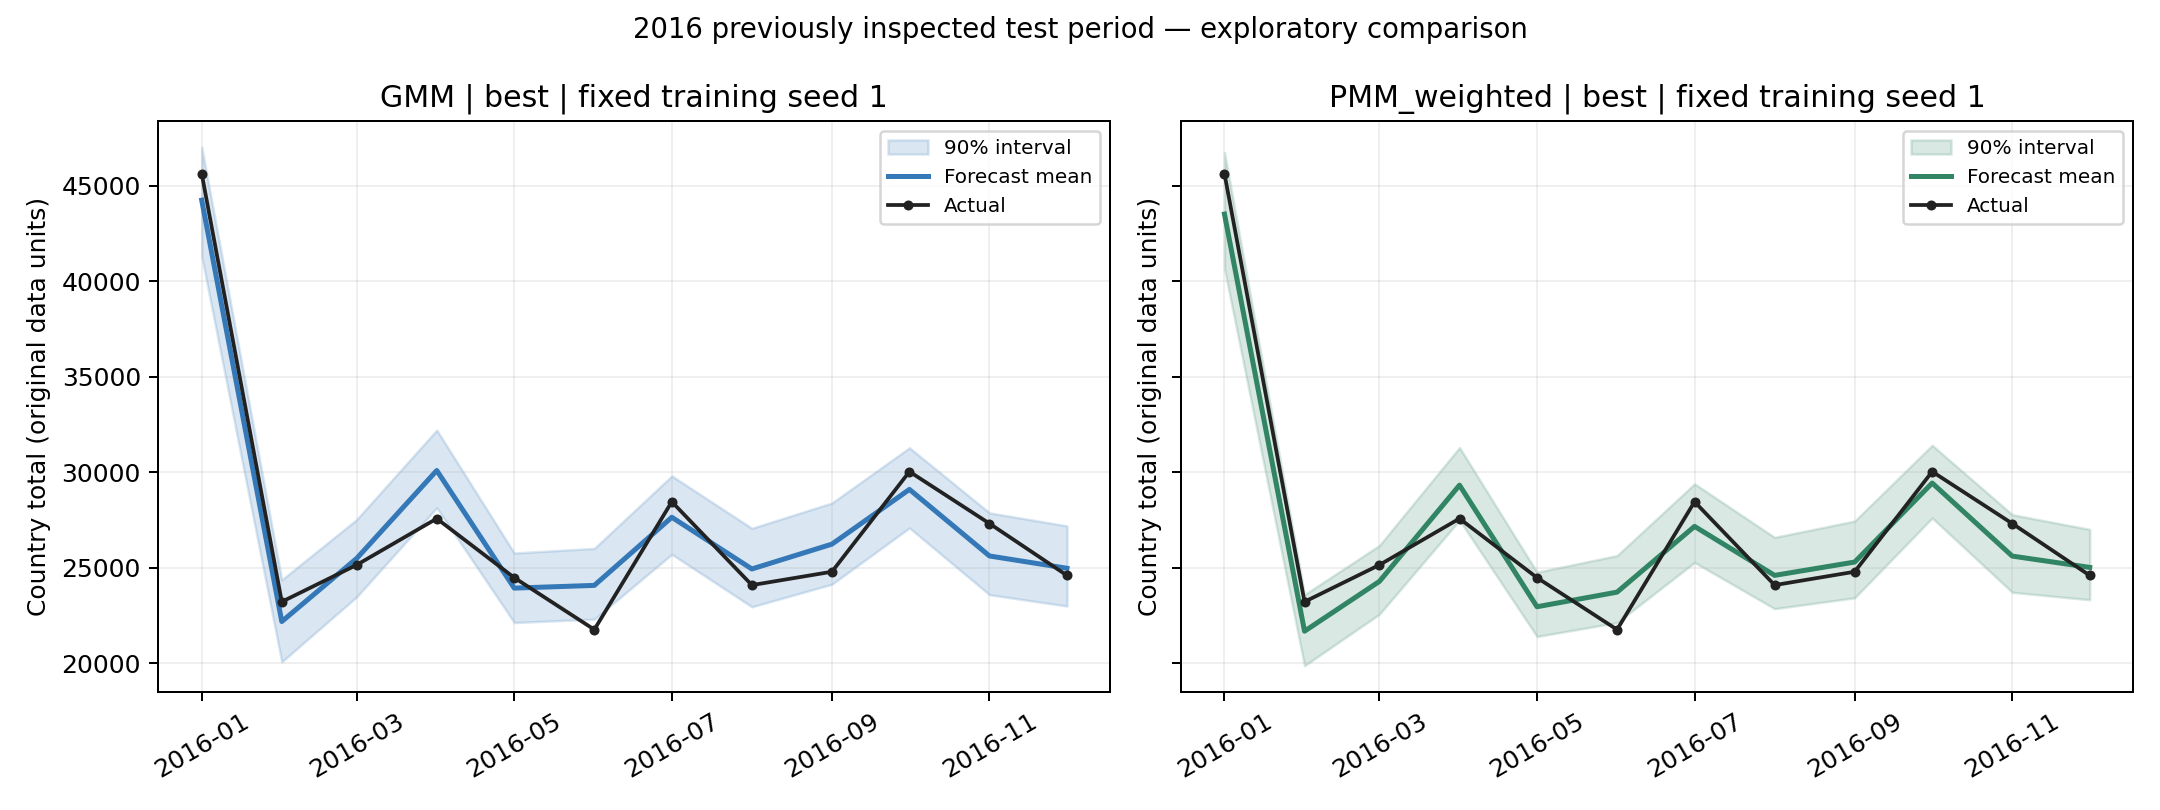

In [4]:
display(pd.read_csv(OUT / 'test_summary.csv'))
display(Image(filename=str(OUT / 'country_test_intervals.png')))


## 下一次修改時保留的檢查

1. `unique_id` 順序必須與 S 一致；S 的底層區塊維持單位矩陣。
2. 確認載入的是選定策略的權重，不能把 early stopping 當成自動還原最佳權重。
3. 保留時間順序切分；只依驗證集選設定。
4. 同時檢查 pooled sCRPS、點預測誤差、各階層偏差與區間覆蓋率。
5. 多個訓練種子要重新訓練；只改預測抽樣種子不能代替。

完整重跑入口見 `PMM_追加檢查計畫.md`。程式會略過已完成的訓練；不同計畫應另設結果目錄。
